# Transformers and flow matching from scratch, in JAX

First of all, let's build a transformer from scratch, and teach it to do regression **in context**: every training
example is a *different* function, and the network only sees a handful of noisy points from it. Nothing about
any one function can actually be stored in the weights, but the model has to work it out from its input.

In the second half, we will reuse the same network as the velocity field of a **flow matching** model, and draw from the posterior
of functions that are consistent with the data.

The functions are drawn from a Gaussian process with a random lengthscale, so the best possible answer is known
exactly. It will be given by `gp_posterior`.

In [1]:
# !pip install -q jax jaxlib matplotlib

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

print("jax", jax.__version__, "| devices:", jax.devices())

jax 0.11.2 | devices: [CpuDevice(id=0)]


## The data


In [2]:
X_MAX = 2.0
NOISE_STD = 0.05
ELL_MIN, ELL_MAX = 0.2, 1.0


def rbf(x1, x2, ell):
    """x1: (b, n), x2: (b, m), ell: (b,) -> (b, n, m)"""
    return jnp.exp(-0.5 * (x1[:, :, None] - x2[:, None, :]) ** 2 / ell[:, None, None] ** 2)


def sample_tasks(key, batch, n_ctx, n_tgt=32, ell=None, x_tgt=None):
    """Draw `batch` random functions, each observed (with noise) at n_ctx context and n_tgt target points.
    Returns xc, yc: (batch, n_ctx)   xt, yt: (batch, n_tgt)   ell: (batch,)"""
    k_ell, k_xc, k_xt, k_y = jax.random.split(key, 4)
    if ell is None:
        ell = jnp.exp(jax.random.uniform(k_ell, (batch,), minval=np.log(ELL_MIN), maxval=np.log(ELL_MAX)))
    ell = jnp.broadcast_to(jnp.asarray(ell, jnp.float32), (batch,))
    xc = jax.random.uniform(k_xc, (batch, n_ctx), minval=-X_MAX, maxval=X_MAX)
    if x_tgt is None:
        xt = jax.random.uniform(k_xt, (batch, n_tgt), minval=-X_MAX, maxval=X_MAX)
    else:
        xt = jnp.broadcast_to(x_tgt, (batch, x_tgt.shape[-1]))
    x = jnp.concatenate([xc, xt], axis=1)
    K = rbf(x, x, ell) + (NOISE_STD**2 + 1e-5) * jnp.eye(x.shape[1])
    y = jnp.einsum("bij,bj->bi", jnp.linalg.cholesky(K), jax.random.normal(k_y, x.shape))
    return xc, y[:, :n_ctx], xt, y[:, n_ctx:], ell


def gp_posterior(xc, yc, xt, ell):
    """Exact GP prediction at xt given (xc, yc), if you knew the lengthscale.
    Returns mean: (b, n_tgt), cov: (b, n_tgt, n_tgt)"""
    ell = jnp.broadcast_to(jnp.asarray(ell, jnp.float32), (xc.shape[0],))
    Kcc = rbf(xc, xc, ell) + NOISE_STD**2 * jnp.eye(xc.shape[1])
    Ktc = rbf(xt, xc, ell)
    Ktt = rbf(xt, xt, ell) + NOISE_STD**2 * jnp.eye(xt.shape[1])
    A = jnp.linalg.solve(Kcc, jnp.swapaxes(Ktc, 1, 2))
    mean = jnp.einsum("bct,bc->bt", A, yc)
    return mean, Ktt - Ktc @ A


xc, yc, xt, yt, ell = sample_tasks(jax.random.key(0), batch=1000, n_ctx=10)
mean, cov = gp_posterior(xc, yc, xt, ell)

print(f"target variance               : {float(yt.var()):.4f}")   # predict 0 everywhere
print(f"GP error, 10 points, true ell : {float(((mean - yt) ** 2).mean()):.4f}")   # the best you can do

target variance               : 0.9791
GP error, 10 points, true ell : 0.1456


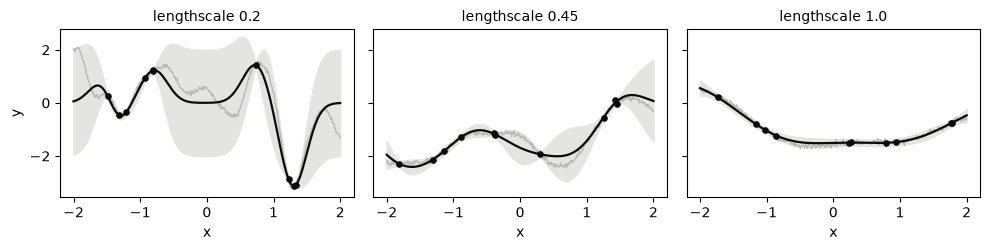

In [3]:
grid = jnp.linspace(-X_MAX, X_MAX, 400)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, ell_, key in zip(axes, [0.2, 0.45, 1.0], jax.random.split(jax.random.key(1), 3)):
    xc, yc, xt, yt, _ = sample_tasks(key, 1, n_ctx=10, ell=ell_, x_tgt=grid)
    mean, cov = gp_posterior(xc, yc, grid[None], ell_)
    std = jnp.sqrt(jnp.diagonal(cov[0]))
    ax.fill_between(np.array(grid), np.array(mean[0] - 2 * std), np.array(mean[0] + 2 * std), color="#e4e4e0")
    ax.plot(np.array(grid), np.array(yt[0]), color="#b8b8b4", lw=1)
    ax.plot(np.array(grid), np.array(mean[0]), color="#0b0b0b", lw=1.6)
    ax.scatter(np.array(xc[0]), np.array(yc[0]), s=14, color="#0b0b0b", zorder=3)
    ax.set_title(f"lengthscale {ell_}", fontsize=10); ax.set_xlabel("x")
axes[0].set_ylabel("y"); plt.tight_layout(); plt.show()

---
## 1. Attention

Every observed point becomes a token `(x, y, 1)`; every point where you want a prediction is also  a token
`(x, 0, 0)`.

Write multi-head self-attention, `attention(params, h, mask)`, where `mask[i, j]` says whether token `i` may look
at token `j`. Then a transformer block: layer norm, attention, residual, MLP, residual.

Choose the mask.  What are targets allowed to look at? should they receive information from other targets?

In [ ]:
from abc import ABC, abstractmethod

from jax import Array


def xavier_normal(key: Array, shape: tuple[int, int]) -> Array:
    """Same XAVIER_NORMAL as in lab 1: std = sqrt(2 / (fan_in + fan_out))."""
    return jax.random.normal(key, shape) * jnp.sqrt(2 / (shape[0] + shape[1]))


class Module(ABC):
    """
        Base class for every piece of the transformer (attention, layer norm, MLP, block, model).

        - params is a dict of arrays, not separate weights/biases lists. A block's params will be
            a dict holding its sub-modules' dicts. JAX treats nested dicts/lists of arrays ("pytrees")
            as one object in grad, jit and optax, so no padding is needed.
        - weights are (in, out) and applied as h @ W. That acts on the last axis only, so it works
              on (batch, tokens, width) without any .T
    """
    params: dict

    @abstractmethod
    def rand_init(self, key: Array) -> dict:
        """Draw fresh params, store them on self.params, and return them."""
        pass

    @abstractmethod
    def forward(self, params: dict, h: Array, *args) -> Array:
        pass


class MultiHeadAttention(Module):
    """
        Multi-Head Self-Attention

        Every token makes a query, a key and a value. Token i's output is the average of the values
        of the tokens it may look at mask[i, j], weighted by softmax_j(q_i • k_j / sqrt(d_head)).

        With n_heads heads, the d_model channels are cut into n_heads groups of d_head = d_model / n_heads,
        and each group does the above on its own. W_o then mixes the heads' results back together.

        # TODO: should eventually use the concatenated output matrix as in 3blue1brown video https://www.youtube.com/watch?v=eMlx5fFNoYc&vl=en 
    """
    d_model: int
    n_heads: int
    d_head: int

    def __init__(
        self,
        d_model: int = 64,
        n_heads: int = 4
    ):
        assert d_model % n_heads == 0, f"d_model={d_model} does not split evenly into {n_heads} heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.params = {}

    def rand_init(self, key: Array) -> dict:
        k_q, k_k, k_v, k_o = jax.random.split(key, 4)
        shape = (self.d_model, self.d_model)   # (in, out)
        self.params = {
            "W_q": xavier_normal(k_q, shape),
            "W_k": xavier_normal(k_k, shape),
            "W_v": xavier_normal(k_v, shape),
            "W_o": xavier_normal(k_o, shape),
        }
        return self.params

    def forward(self, params: dict, h: Array, mask: Array) -> Array:
        """
            h:      (b, n, d_model)     n = n_ctx + n_tgt tokens
            mask:   (n, n) bool         mask[i, j] = token i may look at token j
            returns (b, n, d_model)

            Useful: .reshape, jnp.swapaxes, @ or jnp.einsum, jnp.where, jax.nn.softmax(..., axis=-1)
        """
        b, n, _ = h.shape

        # 1. project every token:  q = h @ W_q, same for k, v                each (b, n, d_model)
        q = h @ params["W_q"]
        k = h @ params["W_k"]
        v = h @ params["W_v"]

        # 2. split heads: cut each token's d_model channels into n_heads groups of d_head,
        #    then move the head axis next to the batch axis so @ runs every head at once
        def split(x: Array) -> Array:
            return x.reshape(b, n, self.n_heads, self.d_head).swapaxes(1, 2)
        q, k, v = split(q), split(k), split(v)                         # each (b, n_heads, n, d_head)

        # 3. every query against every key, within each head
        scores = q @ k.swapaxes(-1, -2) / jnp.sqrt(self.d_head)        # (b, n_heads, n, n)

        # 4. pairs the mask forbids get a score so low that softmax gives them weight 0 (like the -infs in 3b1b)
        scores = jnp.where(mask, scores, -1e9)

        # 5. row i becomes weights over the tokens j that i looks at, summing to 1
        weights = jax.nn.softmax(scores, axis=-1)                      # (b, n_heads, n, n)

        # 6. each token's output = weighted average of the values it looks at
        out = weights @ v                                              # (b, n_heads, n, d_head)

        # 7. merge heads: undo 2 (swap back first, then reshape)
        out = out.swapaxes(1, 2).reshape(b, n, self.d_model)           # (b, n, d_model)

        # 8. W_o mixes the heads' results together
        return out @ params["W_o"]                                     # (b, n, d_model)


def make_mask(n_ctx: int, n_tgt: int) -> Array:
    """
        (n, n) bool, n = n_ctx + n_tgt. Tokens are ordered [context..., targets...].
        mask[i, j] = token i (the row, the one looking) may look at token j.

                         looks at:  context   targets
            row = context        [    A    |    B    ]
            row = targets        [    C    |    D    ]

        Useful: jnp.zeros((n, n), dtype=bool).at[rows, cols].set(True)
    """
    n = n_ctx + n_tgt
    return jnp.zeros((n, n), dtype=bool).at[:, :n_ctx].set(True)


def test_attention_shapes(b: int = 3, n_ctx: int = 5, n_tgt: int = 7, d_model: int = 16, n_heads: int = 4):
    """Batch size, token count, width and heads all differ, so a swapped axis can't hide."""
    print(f"{'-'*50} Test Attention Shapes {'-'*50}")
    attn = MultiHeadAttention(d_model=d_model, n_heads=n_heads)
    params = attn.rand_init(jax.random.key(0))
    h = jax.random.normal(jax.random.key(1), (b, n_ctx + n_tgt, d_model))
    mask = make_mask(n_ctx, n_tgt)

    assert mask.shape == (n_ctx + n_tgt,) * 2 and mask.dtype == bool, f"mask is {mask.shape} {mask.dtype}"
    out = attn.forward(params, h, mask)
    assert out.shape == h.shape, f"expected {h.shape}, got {out.shape}"
    assert jnp.all(jnp.isfinite(out)), "NaN or inf in the output"

    # each batch item run alone must match the batch: catches functions leaking into each other
    out_single = jnp.concatenate([attn.forward(params, h[i:i+1], mask) for i in range(b)])
    assert jnp.allclose(out, out_single, atol=1e-5), "batched output differs from one-at-a-time output"
    print("ok", out.shape)


def test_attention_mask(b: int = 2, n_ctx: int = 5, n_tgt: int = 7, d_model: int = 16, n_heads: int = 4):
    """
        Change one token j and see which outputs move. Output i should move exactly when
        mask[i, j] is True (j's key and value reach i) or i == j (j's own query changed).
        Doesn't assume which mask is right, only that attention obeys the one you chose.
    """
    print(f"{'-'*50} Test Attention Mask {'-'*50}")
    n = n_ctx + n_tgt
    attn = MultiHeadAttention(d_model=d_model, n_heads=n_heads)
    params = attn.rand_init(jax.random.key(0))
    h = jax.random.normal(jax.random.key(1), (b, n, d_model))
    mask = make_mask(n_ctx, n_tgt)
    out = attn.forward(params, h, mask)

    for j in range(n):
        h_j = h.at[:, j].add(3.0)   # move token j only
        moved = jnp.any(jnp.abs(attn.forward(params, h_j, mask) - out) > 1e-5, axis=(0, 2))   # (n,)
        expected = mask[:, j] | (jnp.arange(n) == j)
        assert jnp.array_equal(moved, expected), (
            f"moving token {j}: outputs that moved {moved.astype(int)}, expected {expected.astype(int)}"
        )
    print("ok")


test_attention_shapes()
test_attention_mask()

-------------------------------------------------- Test Attention Shapes --------------------------------------------------
ok (3, 12, 16)
-------------------------------------------------- Test Attention Mask --------------------------------------------------
ok


---
## 2. The transformer

Embed the tokens (a small MLP is fine), stack transformer blocks, and read out a mean and a log-variance at each target.
We will assume a Gaussian negative log-likelihood during training. Some reasonable numbers are width 64, 4 heads, 4 layers.

Each step: get a batch of functions, with a random number of context points between 3 and 30, and 30'ish targets as well. 
Feel free to use jax libraries for the optimiser and weight updates (no need to use your solution from the previous tutorial!). 
The number of context points changes the shapes, so `jax.jit` recompiles once per value. That's fine, otherwise you'd need to add some padding

In [5]:
class LayerNorm(Module):
    """
        Normalise each token's d_model numbers to mean 0, variance 1, on their own
        (not across tokens or the batch), then apply a learned scale (gamma) and shift (beta).

        Keeps every block's input at the same scale however large the running vector h has grown,
        which keeps attention scores and MLP inputs in a range where training is stable.
    """
    d_model: int
    eps: float

    def __init__(
        self,
        d_model: int = 64,
        eps: float = 1e-5
    ):
        self.d_model = d_model
        self.eps = eps
        self.params = {}

    def rand_init(self, key: Array) -> dict:
        # not random: start as "normalise only", i.e. scale 1 and shift 0
        self.params = {
            "gamma": jnp.ones(self.d_model),
            "beta": jnp.zeros(self.d_model),
        }
        return self.params

    def forward(self, params: dict, h: Array) -> Array:
        """h: (..., d_model) -> (..., d_model)"""
        mean = h.mean(axis=-1, keepdims=True)
        var = h.var(axis=-1, keepdims=True)
        return (h - mean) / jnp.sqrt(var + self.eps) * params["gamma"] + params["beta"]


class MLP(Module):
    """
        Plain MLP, applied to the last axis only, so on (b, n, d) it runs on every token separately
        with the same weights. Same layer_sizes idea as lab 1, but layer_sizes now includes the input:
        (64, 256, 64) means 64 -> 256 -> 64.

        Use inside every block (64 -> 256 -> 64), as the token embedding
        (3 -> 64 -> 64), as the output head, and as the section 3 baseline.
    """
    layer_sizes: tuple[int]

    def __init__(
        self,
        layer_sizes: tuple[int],
        activation=jax.nn.gelu
    ):
        self.layer_sizes = layer_sizes
        self.activation = activation
        self.params = {}

    def rand_init(self, key: Array) -> dict:
        keys = jax.random.split(key, len(self.layer_sizes) - 1)
        pairs = list(zip(self.layer_sizes[:-1], self.layer_sizes[1:]))   # (in, out) per layer
        self.params = {
            "weights": [xavier_normal(k, (d_in, d_out)) for k, (d_in, d_out) in zip(keys, pairs)],
            "biases": [jnp.zeros(d_out) for _, d_out in pairs],
        }
        return self.params

    def forward(self, params: dict, h: Array) -> Array:
        """h: (..., layer_sizes[0]) -> (..., layer_sizes[-1])"""
        n_layers = len(params["weights"])
        for i, (W, b) in enumerate(zip(params["weights"], params["biases"])):
            h = h @ W + b
            if i < n_layers - 1:   # no activation after the last layer
                h = self.activation(h)
        return h


class Block(Module):
    """
        One transformer block (pre-norm):

            h = h + attention(LN1(h), mask)     tokens exchange information
            h = h + MLP(LN2(h))                 each token processes what it gathered, on its own

        The "h +" is a residual connection: each step adds a correction to every token's vector
        instead of replacing it, so stacking blocks starts out close to the identity and gradients
        pass straight through the additions.

        params nests the sub-modules' params: {"ln1": {...}, "attn": {...}, "ln2": {...}, "mlp": {...}}
    """
    d_model: int

    def __init__(
        self,
        d_model: int = 64,
        n_heads: int = 4,
        mlp_ratio: int = 4
    ):
        self.d_model = d_model
        self.ln1 = LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.ln2 = LayerNorm(d_model)
        self.mlp = MLP((d_model, mlp_ratio * d_model, d_model))
        self.params = {}

    def rand_init(self, key: Array) -> dict:
        k_attn, k_mlp = jax.random.split(key)
        self.params = {
            "ln1": self.ln1.rand_init(key),
            "attn": self.attn.rand_init(k_attn),
            "ln2": self.ln2.rand_init(key),
            "mlp": self.mlp.rand_init(k_mlp),
        }
        return self.params

    def forward(self, params: dict, h: Array, mask: Array) -> Array:
        """h: (b, n, d_model), mask: (n, n) -> (b, n, d_model)"""
        h = h + self.attn.forward(params["attn"], self.ln1.forward(params["ln1"], h), mask)
        h = h + self.mlp.forward(params["mlp"], self.ln2.forward(params["ln2"], h))
        return h


def test_layernorm(b: int = 3, n: int = 5, d_model: int = 16):
    print(f"{'-'*50} Test LayerNorm {'-'*50}")
    ln = LayerNorm(d_model)
    params = ln.rand_init(jax.random.key(0))
    h = 5 + 3 * jax.random.normal(jax.random.key(1), (b, n, d_model))
    out = ln.forward(params, h)
    assert out.shape == h.shape, f"expected {h.shape}, got {out.shape}"
    assert jnp.allclose(out.mean(axis=-1), 0, atol=1e-5), "each token should have mean 0 over its channels"
    assert jnp.allclose(out.var(axis=-1), 1, atol=1e-3), "each token should have variance 1 over its channels"
    print("ok")


def test_block(b: int = 2, n_ctx: int = 5, n_tgt: int = 7, d_model: int = 16, n_heads: int = 4):
    """
        Same idea as test_attention_mask: in one block, output i moves when token j changes exactly when
        mask[i, j] is True or i == j (residual and MLP act on each token on its own, so they add no new paths).
    """
    print(f"{'-'*50} Test Block {'-'*50}")
    n = n_ctx + n_tgt
    block = Block(d_model=d_model, n_heads=n_heads)
    params = block.rand_init(jax.random.key(0))
    h = jax.random.normal(jax.random.key(1), (b, n, d_model))
    mask = make_mask(n_ctx, n_tgt)
    out = block.forward(params, h, mask)
    assert out.shape == h.shape, f"expected {h.shape}, got {out.shape}"
    assert jnp.all(jnp.isfinite(out)), "NaN or inf in the output"

    for j in range(n):
        # a random direction, not a constant: LayerNorm subtracts each token's mean, so adding 3.0 to every
        # channel would be erased before attention ever saw it
        nudge = 3.0 * jax.random.normal(jax.random.key(j + 2), (d_model,))
        moved = jnp.any(jnp.abs(block.forward(params, h.at[:, j].add(nudge), mask) - out) > 1e-5, axis=(0, 2))
        expected = mask[:, j] | (jnp.arange(n) == j)
        assert jnp.array_equal(moved, expected), (
            f"moving token {j}: outputs that moved {moved.astype(int)}, expected {expected.astype(int)}"
        )
    print("ok", out.shape)


test_layernorm()
test_block()

-------------------------------------------------- Test LayerNorm --------------------------------------------------
ok
-------------------------------------------------- Test Block --------------------------------------------------
ok (2, 12, 16)


In [ ]:
def make_tokens(xc: Array, yc: Array, xt: Array) -> Array:
    """
        xc, yc: (b, n_ctx)   xt: (b, n_tgt)  ->  tokens (b, n_ctx + n_tgt, 3), context first.
        Context token = (x, y, 1). Target token = (x, 0, 0) -- 0 in the index 2 is indicating we're requesting the y value.
    """
    ctx = jnp.stack([xc, yc, jnp.ones_like(xc)], axis=-1)                    # (b, n_ctx, 3)
    tgt = jnp.stack([xt, jnp.zeros_like(xt), jnp.zeros_like(xt)], axis=-1)  # (b, n_tgt, 3)
    return jnp.concatenate([ctx, tgt], axis=1)


class Transformer(Module):
    """
        tokens (b, n, 3)
          -> embed: MLP 3 -> d_model -> d_model, on every token
          -> n_layers Blocks, all using the same mask
          -> final LayerNorm, target rows only
          -> head: MLP d_model -> d_model -> 2, on every target   ->  mean, logvar  each (b, n_tgt)

        n_ctx is read off xc's shape, so it is a plain int even inside jax.jit. jit compiles once per
        new n_ctx, which is the recompilation the notebook mentions.
    """
    def __init__(
        self,
        d_model: int = 64,
        n_heads: int = 4,
        n_layers: int = 4,
        d_in: int = 3,
        d_out: int = 2
    ):
        self.embed = MLP((d_in, d_model, d_model))
        self.blocks = [Block(d_model, n_heads) for _ in range(n_layers)]
        self.ln_final = LayerNorm(d_model)
        self.head = MLP((d_model, d_model, d_out))
        self.params = {}

    def rand_init(self, key: Array) -> dict:
        k_embed, k_head, *k_blocks = jax.random.split(key, 2 + len(self.blocks))
        self.params = {
            "embed": self.embed.rand_init(k_embed),
            "blocks": [block.rand_init(k) for block, k in zip(self.blocks, k_blocks)],
            "ln_final": self.ln_final.rand_init(key),
            "head": self.head.rand_init(k_head),
        }
        return self.params

    def forward(self, params: dict, xc: Array, yc: Array, xt: Array) -> tuple[Array, Array]:
        """xc, yc: (b, n_ctx), xt: (b, n_tgt) -> mean, logvar: each (b, n_tgt)"""
        n_ctx, n_tgt = xc.shape[1], xt.shape[1]
        mask = make_mask(n_ctx, n_tgt)

        h = self.embed.forward(params["embed"], make_tokens(xc, yc, xt))   # (b, n, d_model)
        for block, block_params in zip(self.blocks, params["blocks"]):
            h = block.forward(block_params, h, mask)                       # (b, n, d_model)

        h = self.ln_final.forward(params["ln_final"], h[:, n_ctx:])        # (b, n_tgt, d_model)
        out = self.head.forward(params["head"], h)                         # (b, n_tgt, 2)
        return out[..., 0], out[..., 1]

    def loss(self, params: dict, xc: Array, yc: Array, xt: Array, yt: Array) -> Array:
        """
            Gaussian negative log-likelihood of yt under N(mean, exp(logvar)).
        """
        mean, logvar = self.forward(params, xc, yc, xt)
        return 0.5 * jnp.mean(logvar + (yt - mean) ** 2 / jnp.exp(logvar))


class Adam:
    """
        Adam optimizer.
    """
    def __init__(
        self,
        lr: float = 1e-3,
        beta1: float = 0.9,
        beta2: float = 0.999,
        eps: float = 1e-8
    ):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps

    def init(self, params: dict) -> dict:
        zeros = jax.tree_util.tree_map(jnp.zeros_like, params)
        return {"m": zeros, "v": zeros, "t": jnp.array(0)}

    def update(self, params: dict, grads: dict, state: dict) -> tuple[dict, dict]:
        b1, b2 = self.beta1, self.beta2
        t = state["t"] + 1
        m = jax.tree_util.tree_map(lambda m, g: b1 * m + (1 - b1) * g, state["m"], grads)
        v = jax.tree_util.tree_map(lambda v, g: b2 * v + (1 - b2) * g ** 2, state["v"], grads)

        def step(p, m, v):
            m_hat = m / (1 - b1 ** t)   # bias corrections, as in lab 1
            v_hat = v / (1 - b2 ** t)
            return p - self.lr * m_hat / (jnp.sqrt(v_hat) + self.eps)

        return jax.tree_util.tree_map(step, params, m, v), {"m": m, "v": v, "t": t}


def make_train_step(model: Module, optimizer: Adam):
    """One jitted step: loss and grads (jax does the backward pass), then the Adam update."""
    @jax.jit
    def train_step(params, opt_state, xc, yc, xt, yt):
        loss, grads = jax.value_and_grad(model.loss)(params, xc, yc, xt, yt)
        params, opt_state = optimizer.update(params, grads, opt_state)
        return params, opt_state, loss
    return train_step


def train(
    model: Module,
    params: dict,
    optimizer: Adam,
    n_steps: int = 5000,
    batch: int = 64,
    n_tgt: int = 32,
    n_ctx_range: tuple[int, int] = (3, 30),
    seed: int = 0,
    log_every: int = 500
) -> tuple[dict, list[float]]:
    train_step = make_train_step(model, optimizer)
    opt_state = optimizer.init(params)
    rng = np.random.default_rng(seed)
    key = jax.random.key(seed)
    losses = []

    for step in range(n_steps):
        key, k_data = jax.random.split(key)
        # a plain Python int: it sets array shapes, so it can't be a traced jax value
        n_ctx = int(rng.integers(n_ctx_range[0], n_ctx_range[1] + 1))
        xc, yc, xt, yt, _ = sample_tasks(k_data, batch, n_ctx, n_tgt)
        params, opt_state, loss = train_step(params, opt_state, xc, yc, xt, yt)
        losses.append(float(loss))
        if step % log_every == 0 or step == n_steps - 1:
            print(f"step {step:5d}   loss {np.mean(losses[-log_every:]):+.4f}")

    return params, losses


def eval_mse(model: Module, params: dict, n_ctx: int, batch: int = 1000, seed: int = 123) -> tuple[float, float]:
    """MSE of the model's mean and of the exact GP mean, on the same fixed test functions."""
    xc, yc, xt, yt, ell = sample_tasks(jax.random.key(seed), batch, n_ctx)
    mean, _ = model.forward(params, xc, yc, xt)
    gp_mean, _ = gp_posterior(xc, yc, xt, ell)
    return float(((mean - yt) ** 2).mean()), float(((gp_mean - yt) ** 2).mean())


def test_transformer_shapes(b: int = 3, n_ctx: int = 5, n_tgt: int = 7):
    print(f"{'-'*50} Test Transformer Shapes {'-'*50}")
    model = Transformer(d_model=16, n_heads=4, n_layers=2)
    params = model.rand_init(jax.random.key(0))
    xc, yc, xt, yt, _ = sample_tasks(jax.random.key(1), b, n_ctx, n_tgt)
    mean, logvar = model.forward(params, xc, yc, xt)
    assert mean.shape == (b, n_tgt) and logvar.shape == (b, n_tgt), f"got {mean.shape}, {logvar.shape}"
    assert jnp.isfinite(model.loss(params, xc, yc, xt, yt)), "loss is not finite"
    print("ok", mean.shape)


def test_targets_independent(b: int = 3, n_ctx: int = 5, n_tgt: int = 7):
    """Your mask rule, end to end: the prediction at a target doesn't depend on which other targets you asked about."""
    print(f"{'-'*50} Test Targets Independent {'-'*50}")
    model = Transformer(d_model=16, n_heads=4, n_layers=2)
    params = model.rand_init(jax.random.key(0))
    xc, yc, xt, _, _ = sample_tasks(jax.random.key(1), b, n_ctx, n_tgt)
    mean_all, logvar_all = model.forward(params, xc, yc, xt)
    for i in range(n_tgt):
        mean_i, logvar_i = model.forward(params, xc, yc, xt[:, i:i+1])   # ask about target i alone
        assert jnp.allclose(mean_all[:, i], mean_i[:, 0], atol=1e-5), f"target {i}'s mean depends on the other targets"
        assert jnp.allclose(logvar_all[:, i], logvar_i[:, 0], atol=1e-5), f"target {i}'s logvar depends on the other targets"
    print("ok")


test_transformer_shapes()
test_targets_independent()

-------------------------------------------------- Test Transformer Shapes --------------------------------------------------
ok (3, 7)
-------------------------------------------------- Test Targets Independent --------------------------------------------------
ok


In [7]:
model = Transformer()
params = model.rand_init(jax.random.key(0))
params, losses = train(model, params, Adam(lr=1e-3), n_steps=5000)

for n_ctx in [3, 5, 10, 20, 30]:
    m, g = eval_mse(model, params, n_ctx)
    print(f"n_ctx {n_ctx:2d}   transformer {m:.4f}   GP {g:.4f}")

step     0   loss +1.0461
step   500   loss -0.1796
step  1000   loss -0.6658
step  1500   loss -0.9034
step  2000   loss -0.9888
step  2500   loss -1.0584
step  3000   loss -1.1109
step  3500   loss -1.1261
step  4000   loss -1.1593
step  4500   loss -1.1779
step  4999   loss -1.2834
n_ctx  3   transformer 0.5872   GP 0.5281
n_ctx  5   transformer 0.4088   GP 0.3523
n_ctx 10   transformer 0.1884   GP 0.1520
n_ctx 20   transformer 0.0582   GP 0.0387
n_ctx 30   transformer 0.0229   GP 0.0125


---
## 3. An MLP, for comparison

Give an MLP the same job: flatten the context, zero-padded up to 30 points with a mask, and append the query
`x`. Train it the same way.

In [10]:
class MLPBaseline(Module):
    """
        The same job without attention. For every target, one input row of 3 * max_ctx + 1 numbers:

            [ x_1 .. x_30 | y_1 .. y_30 | m_1 .. m_30 | x_query ]     m_i = 1 for a real point, 0 for padding

        Fewer than max_ctx points: zero-pad and mark the padding with m = 0.
        More than max_ctx points: keep only the first max_ctx. The input has a fixed number of slots,
        so extra points have nowhere to go. That's a real limit of this design, not a bug to fix.

        Same forward / loss interface as Transformer, so train, eval_mse and plot_predictions work unchanged.
    """
    max_ctx: int

    def __init__(
        self,
        max_ctx: int = 30,
        hidden: tuple[int] = (256, 256, 256),
        d_out: int = 2
    ):
        self.max_ctx = max_ctx
        self.mlp = MLP((3 * max_ctx + 1, *hidden, d_out))
        self.params = {}

    def rand_init(self, key: Array) -> dict:
        self.params = {"mlp": self.mlp.rand_init(key)}
        return self.params

    def make_inputs(self, xc: Array, yc: Array, xt: Array) -> Array:
        """xc, yc: (b, n_ctx), xt: (b, n_tgt) -> (b, n_tgt, 3 * max_ctx + 1)"""
        xc, yc = xc[:, :self.max_ctx], yc[:, :self.max_ctx]   # drop points beyond the last slot
        b, n_ctx = xc.shape
        n_tgt = xt.shape[1]
        pad = ((0, 0), (0, self.max_ctx - n_ctx))
        ctx = jnp.concatenate([
            jnp.pad(xc, pad),
            jnp.pad(yc, pad),
            jnp.pad(jnp.ones_like(xc), pad),   # the mask: 1 = real point, 0 = padding
        ], axis=1)                              # (b, 3 * max_ctx)
        ctx = jnp.broadcast_to(ctx[:, None, :], (b, n_tgt, ctx.shape[1]))   # same context for every target
        return jnp.concatenate([ctx, xt[..., None]], axis=-1)

    def forward(self, params: dict, xc: Array, yc: Array, xt: Array) -> tuple[Array, Array]:
        """xc, yc: (b, n_ctx), xt: (b, n_tgt) -> mean, logvar: each (b, n_tgt)"""
        out = self.mlp.forward(params["mlp"], self.make_inputs(xc, yc, xt))   # (b, n_tgt, 2)
        return out[..., 0], out[..., 1]

    def loss(self, params: dict, xc: Array, yc: Array, xt: Array, yt: Array) -> Array:
        """Same Gaussian negative log-likelihood as the transformer."""
        mean, logvar = self.forward(params, xc, yc, xt)
        return 0.5 * jnp.mean(logvar + (yt - mean) ** 2 / jnp.exp(logvar))


def n_params(params: dict) -> int:
    """Total number of trainable numbers in a params pytree."""
    return sum(leaf.size for leaf in jax.tree_util.tree_leaves(params))


def test_mlp_baseline(b: int = 3, n_tgt: int = 7):
    print(f"{'-'*50} Test MLP Baseline {'-'*50}")
    model = MLPBaseline(max_ctx=30)
    params = model.rand_init(jax.random.key(0))
    for n_ctx in (5, 30, 40):   # padded, exactly full, truncated
        xc, yc, xt, yt, _ = sample_tasks(jax.random.key(n_ctx), b, n_ctx, n_tgt)
        inputs = model.make_inputs(xc, yc, xt)
        assert inputs.shape == (b, n_tgt, 91), f"n_ctx={n_ctx}: inputs {inputs.shape}"
        n_real = min(n_ctx, 30)
        assert jnp.all(inputs[..., 60:60 + n_real] == 1) and jnp.all(inputs[..., 60 + n_real:90] == 0), f"n_ctx={n_ctx}: mask slots wrong"
        assert jnp.all(inputs[..., 90] == xt), f"n_ctx={n_ctx}: last slot should be the query x"
        mean, logvar = model.forward(params, xc, yc, xt)
        assert mean.shape == (b, n_tgt) and logvar.shape == (b, n_tgt), f"n_ctx={n_ctx}: got {mean.shape}"
    print("ok")


test_mlp_baseline()

-------------------------------------------------- Test MLP Baseline --------------------------------------------------
ok


In [12]:
mlp = MLPBaseline()
mlp_params = mlp.rand_init(jax.random.key(0))
print("params: transformer", n_params(params), "  MLP", n_params(mlp_params))
mlp_params, mlp_losses = train(mlp, mlp_params, Adam(lr=1e-3), n_steps=20000, log_every=2500)

for n_ctx in [3, 5, 10, 20, 30]:
    t, g = eval_mse(model, params, n_ctx)
    m, _ = eval_mse(mlp, mlp_params, n_ctx)
    print(f"n_ctx {n_ctx:2d}   transformer {t:.4f}   MLP {m:.4f}   GP {g:.4f}")

params: transformer 207746   MLP 155650
step     0   loss +0.5159
step  2500   loss +0.1921
step  5000   loss +0.1197
step  7500   loss +0.0041
step 10000   loss -0.0947
step 12500   loss -0.1655
step 15000   loss -0.2165
step 17500   loss -0.2686
step 19999   loss -0.3036
n_ctx  3   transformer 0.5872   MLP 0.6187   GP 0.5281
n_ctx  5   transformer 0.4088   MLP 0.4687   GP 0.3523
n_ctx 10   transformer 0.1884   MLP 0.3227   GP 0.1520
n_ctx 20   transformer 0.0582   MLP 0.2823   GP 0.0387
n_ctx 30   transformer 0.0229   MLP 0.2940   GP 0.0125


---
## 4. Results 

- **Test error against the number of context points**, from 3 to 80, log-log, for the transformer, the MLP,
  and `gp_posterior` with the true lengthscale
- What happens to each model's predictions when you **shuffle the context points**?
- Plot something I didn't ask for!

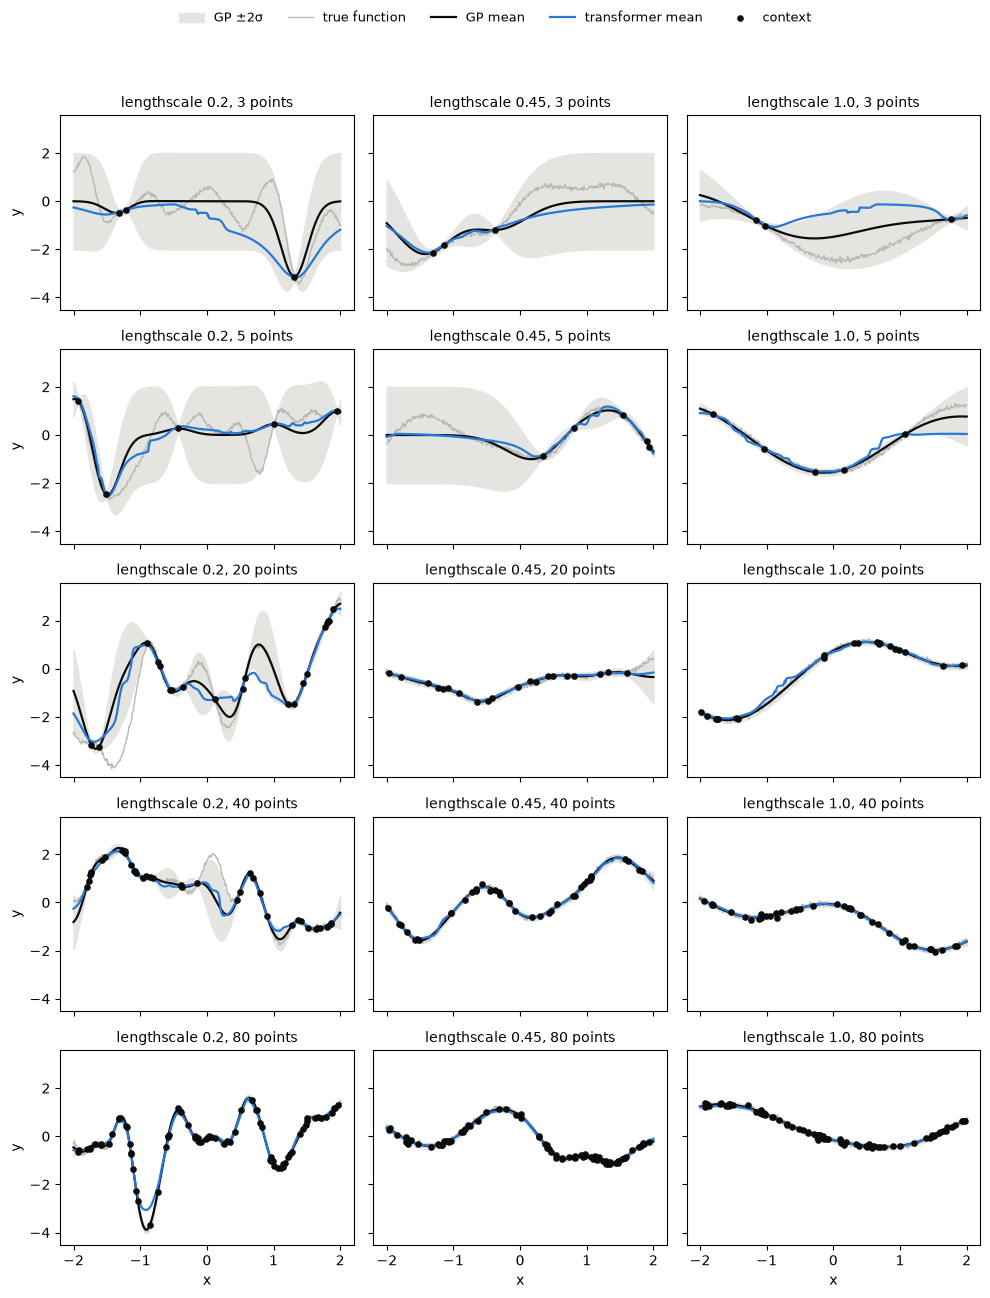

In [19]:
# NOTE: Plots made with lots of Claude's lovely help.

def plot_predictions(model, params, n_ctxs=(3, 5, 20, 40, 80), ells=(0.2, 0.45, 1.0), seed=1, name=""):
    """
        One random function per panel. Rows: number of context points. Columns: lengthscale.
        Transformer: mean (blue line) and mean ± 2σ (blue dashes), σ = exp(logvar / 2).
        Exact GP with the true lengthscale: mean (black line) and ± 2σ (grey band), the best possible answer.
    """
    BLUE = "#2a78d6"
    grid = jnp.linspace(-X_MAX, X_MAX, 400)
    keys = jax.random.split(jax.random.key(seed), len(n_ctxs) * len(ells))
    fig, axes = plt.subplots(len(n_ctxs), len(ells), figsize=(10, 2.6 * len(n_ctxs)),
                             sharex=True, sharey=True, squeeze=False)

    for r, n_ctx in enumerate(n_ctxs):
        for c, ell_ in enumerate(ells):
            ax = axes[r, c]
            xc, yc, _, yt, _ = sample_tasks(keys[r * len(ells) + c], 1, n_ctx=n_ctx, ell=ell_, x_tgt=grid)

            gp_mean, gp_cov = gp_posterior(xc, yc, grid[None], ell_)
            gp_std = jnp.sqrt(jnp.diagonal(gp_cov[0]))
            mean, logvar = model.forward(params, xc, yc, grid[None])
            std = jnp.exp(0.5 * logvar[0])

            g, gm, gs, m, s = (np.array(a) for a in (grid, gp_mean[0], gp_std, mean[0], std))
            ax.fill_between(g, gm - 2 * gs, gm + 2 * gs, color="#e4e4e0", label="GP ±2σ")
            ax.plot(g, np.array(yt[0]), color="#b8b8b4", lw=1, label="true function")
            ax.plot(g, gm, color="#0b0b0b", lw=1.6, label="GP mean")
            ax.plot(g, m, color=BLUE, lw=1.6, label=f"{name} mean")
            # ax.plot(g, m + 2 * s, color=BLUE, lw=1, ls="--", label=f"{name} ±2σ")
            # ax.plot(g, m - 2 * s, color=BLUE, lw=1, ls="--")
            ax.scatter(np.array(xc[0]), np.array(yc[0]), s=14, color="#0b0b0b", zorder=3, label="context")
            ax.set_title(f"lengthscale {ell_}, {n_ctx} points", fontsize=10)

    for ax in axes[-1]:
        ax.set_xlabel("x")
    for ax in axes[:, 0]:
        ax.set_ylabel("y")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), frameon=False, fontsize=9)
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()


plot_predictions(model, params, name="transformer")

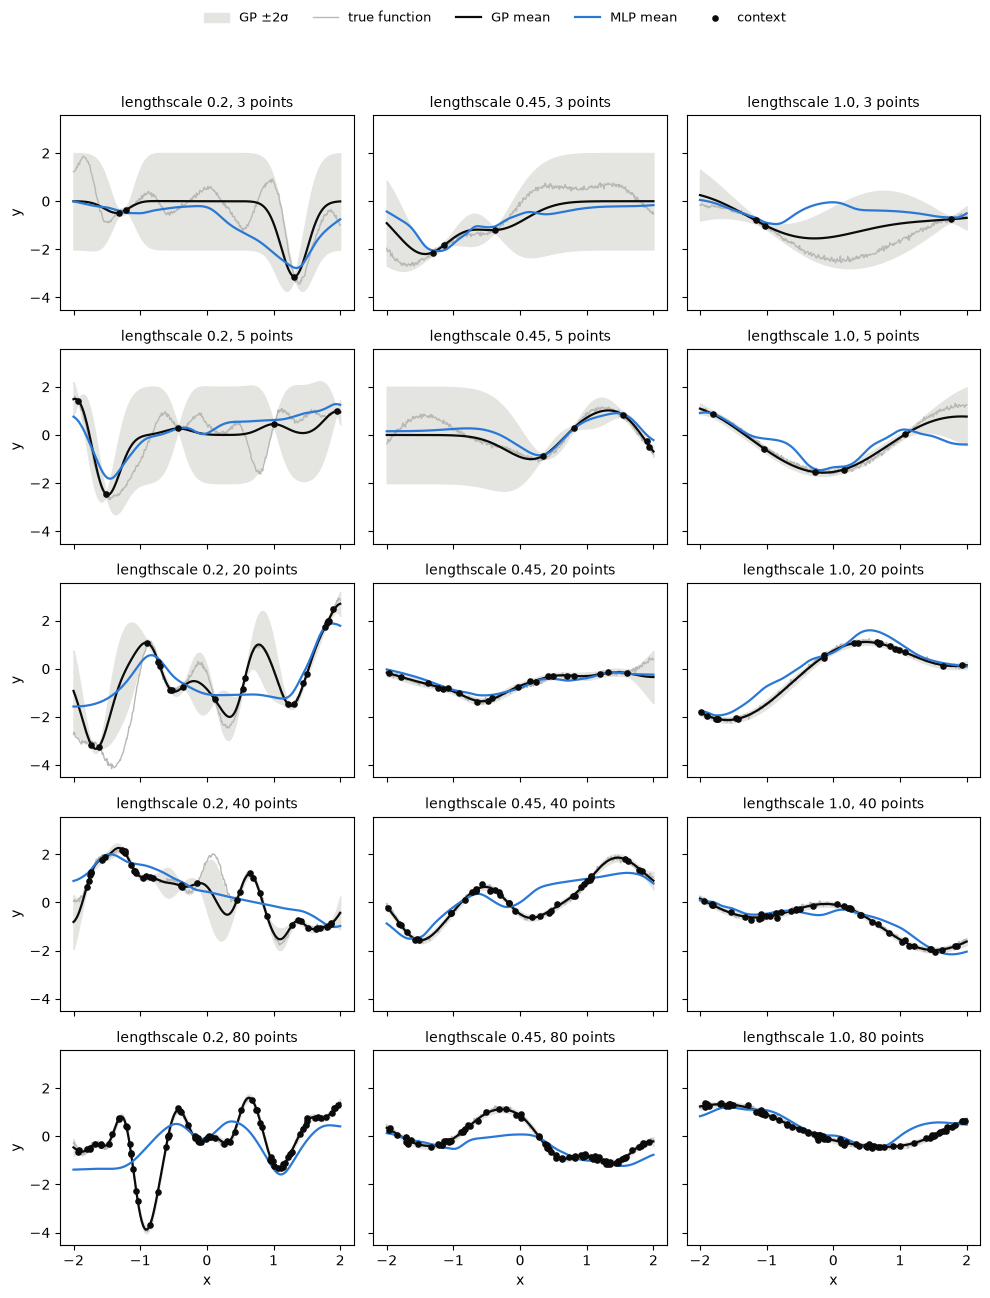

In [20]:
plot_predictions(mlp, mlp_params, name="MLP")

---
## 5. Flow matching

Now generate posteriors over functions. Target tokens carry a noisy value $y_t$ instead of 0, the time $t$ is embedded and added
to every token, and the head outputs one velocity per target. Same network as before.

Train on the straight path from noise $\epsilon \sim \mathcal{N}(0, 1)$ to data:

$$y_t = (1-t)\,\epsilon + t\,y, \qquad \mathcal{L} = \big\| v_\theta(y_t, t \mid \text{context}) - (y - \epsilon) \big\|^2$$

Sample by integrating $dy/dt = v_\theta$ from $t=0$ to $1$ with Euler, 50 steps.